# Calentamientos: el flujo de Kuramoto

## 1. Calentamiento 1: el grafo completo $K_n$

**Objetivo** (slide 26/34): simular el flujo gradiente $\dot\theta = -\nabla\mathcal{E}(\theta)$ en $K_n$ y verificar que **siempre sincroniza**.

De paso armamos el *pipeline básico* que se reutiliza en los calentamientos 2 ($C_n$) y 3 ($C_{n,k}$):

1. **simulador**: descenso de gradiente sobre la energía;
2. **test de estabilidad**: autovalores del Hessiano en el punto final.

> **Colab:** este notebook no necesita instalar nada (Colab ya trae `numpy` y `matplotlib`). *Entorno de ejecución → Ejecutar todas*.

### 1.1 Recordatorio

- Fases $\theta_v \in \mathbb{T} = (-\pi, \pi]$, una por vértice. Matriz de adyacencia $W$ ($w_{uv}=1$ si hay arista).
- Dinámica: $\dot\theta_v = \sum_u w_{uv}\sin(\theta_u - \theta_v)$.
- Energía: $\mathcal{E}(\theta) = \tfrac12 \sum_{u,v} w_{uv}\bigl(1-\cos(\theta_u-\theta_v)\bigr)$, y la dinámica es $\dot\theta = -\nabla\mathcal{E}$.
- Hessiano: es un **Laplaciano con pesos** $w_{uv}\cos(\theta_u-\theta_v)$:
$$H_{uv} = -w_{uv}\cos(\theta_u-\theta_v)\ (u\neq v), \qquad H_{vv} = \sum_u w_{uv}\cos(\theta_u-\theta_v).$$
  Siempre tiene un autovalor $0$ con autovector $(1,\dots,1)$: rotar todas las fases no cambia la energía.
- Clasificación de un equilibrio por el Hessiano (ignorando ese $0$):
  - todos los demás $>0$ → **mínimo local estricto** (atrapa con probabilidad positiva);
  - alguno $<0$ → **silla o máximo** (solo atrapa desde un conjunto de medida cero).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=0)
plt.rcParams["figure.dpi"] = 110

### 1.2 Funciones

Todas reciben la matriz de adyacencia `W`, así que sirven para cualquier grafo (no solo $K_n$).

Convención: `D[v, u] = θ_u − θ_v` (fila = el oscilador que se mueve, columna = el vecino que tira).

In [2]:
def grafo_completo(n):
    """K_n: todos con todos, sin self-loops."""
    return np.ones((n, n)) - np.eye(n)


def diferencias_fase(theta):
    """Matriz D con D[v, u] = θ_u − θ_v."""
    return theta[None, :] - theta[:, None]


def velocidad(theta, W):
    """θ̇_v = Σ_u w_uv sin(θ_u − θ_v), que es −∇E."""
    return (W * np.sin(diferencias_fase(theta))).sum(axis=1)


def energia(theta, W):
    """E = ½ Σ_{u,v} w_uv (1 − cos(θ_u − θ_v))."""
    return 0.5 * (W * (1 - np.cos(diferencias_fase(theta)))).sum()


def parametro_orden(theta):
    """r = (1/n) Σ e^{iθ_v}: |r| mide cuán agrupadas están las fases y arg r hacia dónde."""
    return np.exp(1j * theta).mean()


def hessiano(theta, W):
    """Hessiano de E: Laplaciano con pesos w_uv cos(θ_u − θ_v)."""
    C = W * np.cos(diferencias_fase(theta))
    return np.diag(C.sum(axis=1)) - C


def wrap(x):
    """Lleva ángulos a (−π, π]."""
    return np.angle(np.exp(1j * x))

#### El simulador: descenso de gradiente

Discretizamos $\dot\theta = -\nabla\mathcal{E}$ con el método de Euler:
$$\theta_{k+1} = \theta_k + h\,\dot\theta(\theta_k) = \theta_k - h\,\nabla\mathcal{E}(\theta_k),$$
que es **exactamente** el descenso de gradiente de la slide 8.

**Paso $h$.** Por Gershgorin, los autovalores del Hessiano están acotados por $L = 2\max_v \deg(v)$. Con $h \le 1/L$ el descenso de gradiente **garantiza** que la energía no sube en ningún paso. Usamos $h = 1/(2\max\deg)$.

**Criterio de parada:** $\|\nabla\mathcal{E}\| < $ `tol`, o sea, llegamos (numéricamente) a un equilibrio.

In [3]:
def simular(theta0, W, h=None, tol=1e-10, max_pasos=200_000, guardar=True):
    """Descenso de gradiente (Euler) sobre E desde theta0, hasta que ‖θ̇‖ < tol.

    El paso por defecto h = 1/(2·grado máximo) garantiza que la energía no suba.
    Devuelve el estado final y, si guardar=True, la historia con t, E y r.
    """
    if h is None:
        h = 1.0 / (2 * W.sum(axis=1).max())
    theta = np.array(theta0, dtype=float)
    historia = [theta.copy()]
    convergio = False
    for paso in range(1, max_pasos + 1):
        v = velocidad(theta, W)
        if np.linalg.norm(v) < tol:
            convergio = True
            break
        theta = theta + h * v
        if guardar:
            historia.append(theta.copy())
    salida = {"theta": theta, "pasos": paso, "convergio": convergio, "h": h}
    if guardar:
        historia = np.array(historia)
        salida["t"] = h * np.arange(len(historia))
        salida["historia"] = historia
        salida["E"] = np.array([energia(th, W) for th in historia])
        salida["r"] = np.array([parametro_orden(th) for th in historia])
    return salida


def clasificar(theta, W, tol=1e-6):
    """Clasifica un equilibrio por los autovalores del Hessiano (el 0 de la rotación global siempre está)."""
    autovalores = np.linalg.eigvalsh(hessiano(theta, W))
    escala = max(1.0, np.abs(autovalores).max())
    negativos = int(np.sum(autovalores < -tol * escala))
    positivos = int(np.sum(autovalores > tol * escala))
    nulos = len(autovalores) - negativos - positivos
    if negativos == 0 and nulos == 1:
        tipo = "mínimo estricto"
    elif positivos == 0 and nulos == 1:
        tipo = "máximo estricto"
    elif negativos > 0:
        tipo = "silla" if positivos > 0 else "máximo (degenerado)"
    else:
        tipo = "degenerado"
    return tipo, autovalores

### 1.3 Chequeos de sanidad

Antes de confiar en el simulador, verificamos numéricamente tres cuentas que hicimos a mano:

1. `velocidad` es **menos el gradiente** de `energia` (comparando con diferencias finitas).
2. En $K_n$, la **identidad mágica** (slide 12): $\mathcal{E}_{K_n}(\theta) = \frac{n^2}{2}\bigl(1-|r|^2\bigr)$.
3. En $K_n$, cada oscilador es arrastrado hacia el centro de masa: $\dot\theta_v = n\,|r|\sin(\psi-\theta_v)$.

Los cuatro números tienen que ser chicos (del orden de $10^{-9}$ o menos). Si lo son, las fórmulas del código coinciden con las cuentas.

In [4]:
n = 7
W = grafo_completo(n)
theta = rng.uniform(-np.pi, np.pi, n)
eps = 1e-6

# 1. velocidad == −∇E  (diferencias finitas centradas)
gradiente_fd = np.zeros(n)
for v, e in enumerate(np.eye(n)):
    gradiente_fd[v] = (energia(theta + eps * e, W) - energia(theta - eps * e, W)) / (2 * eps)
print("‖velocidad + ∇E‖    =", np.linalg.norm(velocidad(theta, W) + gradiente_fd))

# 2. identidad mágica
r = parametro_orden(theta)
print("|E − n²/2 (1−|r|²)| =", abs(energia(theta, W) - n**2 / 2 * (1 - abs(r)**2)))

# 3. arrastre hacia el centro de masa
psi = np.angle(r)
arrastre = n * abs(r) * np.sin(psi - theta)
print("‖θ̇ − n|r|sin(ψ−θ)‖  =", np.linalg.norm(velocidad(theta, W) - arrastre))

# 4. el Hessiano coincide con diferencias finitas del gradiente
hessiano_fd = np.zeros((n, n))
for v, e in enumerate(np.eye(n)):
    hessiano_fd[v] = (velocidad(theta - eps * e, W) - velocidad(theta + eps * e, W)) / (2 * eps)
print("‖H − H_fd‖          =", np.linalg.norm(hessiano(theta, W) - hessiano_fd))

‖velocidad + ∇E‖    = 2.2356308407170887e-09
|E − n²/2 (1−|r|²)| = 0.0
‖θ̇ − n|r|sin(ψ−θ)‖  = 1.602148379482783e-15
‖H − H_fd‖          = 9.958581631364004e-10


### 1.4 Experimento A: una corrida

$n = 10$ osciladores con fases iniciales al azar (uniformes en el círculo). Miramos:

- la **fase relativa** $\theta_v - \psi(t)$ de cada oscilador respecto del centro de masa (sincronizar = todas van a $0$);
- la **energía** $\mathcal{E}(t)$, que tiene que bajar siempre y llegar a $0$;
- el **parámetro de orden** $|r(t)|$, que tiene que llegar a $1$.

pasos: 37, convergió: True, tiempo final: 2.00
E inicial = 34.812   E final = 0.00e+00   |r| final = 1.000000000000
¿la energía nunca subió? True
clasificación del punto final: mínimo estricto


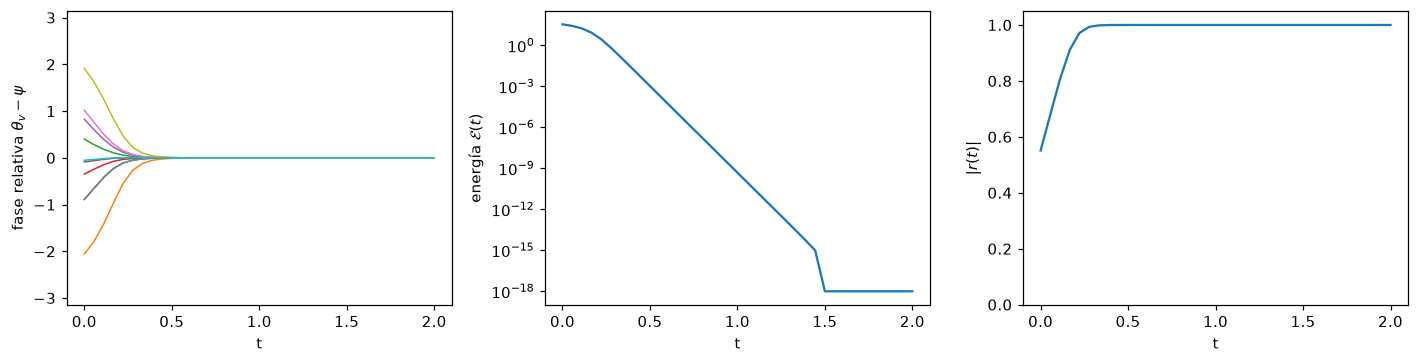

In [5]:
n = 10
W = grafo_completo(n)
theta0 = rng.uniform(-np.pi, np.pi, n)
sim = simular(theta0, W)

t = sim["t"]
E = sim["E"]
r = sim["r"]
fase_relativa = wrap(sim["historia"] - np.angle(r)[:, None])   # fase relativa al centro de masa

print(f"pasos: {sim['pasos']}, convergió: {sim['convergio']}, tiempo final: {t[-1]:.2f}")
print(f"E inicial = {E[0]:.3f}   E final = {E[-1]:.2e}   |r| final = {abs(r[-1]):.12f}")
print("¿la energía nunca subió?", bool(np.all(np.diff(E) <= 1e-12)))
print("clasificación del punto final:", clasificar(sim["theta"], W)[0])

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].plot(t, fase_relativa, lw=1)
ax[0].set(ylabel=r"fase relativa $\theta_v-\psi$", xlabel="t", ylim=(-np.pi, np.pi))
ax[1].semilogy(t, np.maximum(E, 1e-18))
ax[1].set(ylabel=r"energía $\mathcal{E}(t)$", xlabel="t")
ax[2].plot(t, np.abs(r))
ax[2].set(ylabel=r"$|r(t)|$", xlabel="t", ylim=(0, 1.05))
plt.tight_layout()
plt.show()

#### Fotos de las partículas en el círculo

Cada oscilador es una partícula $e^{i\theta_v}$; la flecha es el parámetro de orden $r$ (centro de masa).

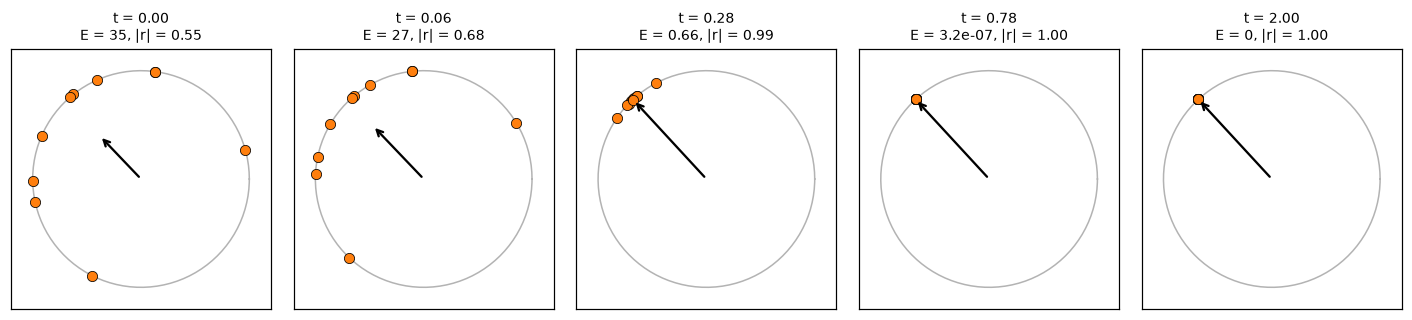

In [6]:
def dibujar_circulo(ax, theta, titulo=""):
    """Partículas e^{iθ_v} sobre el círculo unitario y la flecha del parámetro de orden r."""
    s = np.linspace(0, 2 * np.pi, 200)
    ax.plot(np.cos(s), np.sin(s), color="0.7", lw=1)
    ax.scatter(np.cos(theta), np.sin(theta), s=45, color="tab:orange", zorder=3, edgecolor="k", lw=0.5)
    r = parametro_orden(theta)
    ax.annotate("", xy=(r.real, r.imag), xytext=(0, 0), arrowprops=dict(arrowstyle="->", lw=1.5))
    ax.set(aspect="equal", xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), xticks=[], yticks=[])
    ax.set_title(titulo, fontsize=9)


indices = np.unique(np.geomspace(1, len(t), 5).astype(int) - 1)
fig, ax = plt.subplots(1, len(indices), figsize=(2.6 * len(indices), 2.8))
for eje, i in zip(ax, indices):
    titulo = f"t = {t[i]:.2f}\nE = {E[i]:.2g}, |r| = {abs(r[i]):.2f}"
    dibujar_circulo(eje, sim["historia"][i], titulo)
plt.tight_layout()
plt.show()

### 1.5 Experimento B: muchas corridas

Para cada $n \in \{3, 5, 10, 20, 50, 100\}$ largamos 200 condiciones iniciales al azar y miramos dónde termina cada una:

- ¿terminó **sincronizada**? (criterio: $1-|r| < 10^{-8}$);
- ¿qué dice el **Hessiano** del punto final?

Si $K_n$ sincroniza globalmente, esperamos **100 %** sincronizadas y todas "mínimo estricto".

In [ ]:
ns = [3, 5, 10, 20, 50, 100]
corridas = 200

print(f"{'n':>4} {'sincronizadas':>14} {'mín. estricto':>14} {'pasos (mediana)':>16} {'máx 1−|r|':>11}")
for n in ns:
    W = grafo_completo(n)
    sincronizadas = 0
    estrictos = 0
    pasos = []
    brechas = []
    for _ in range(corridas):
        sim = simular(rng.uniform(-np.pi, np.pi, n), W, guardar=False)
        brecha = 1 - abs(parametro_orden(sim["theta"]))
        sincronizadas += brecha < 1e-8
        estrictos += clasificar(sim["theta"], W)[0] == "mínimo estricto"
        pasos.append(sim["pasos"])
        brechas.append(brecha)
    print(f"{n:>4} {sincronizadas:>9}/{corridas} {estrictos:>9}/{corridas} {int(np.median(pasos)):>16} {max(brechas):>11.1e}")

   n  sincronizadas  mín. estricto  pasos (mediana)   máx 1−|r|
   3       200/200       200/200               21     2.2e-16
   5       200/200       200/200               31     1.1e-16
  10       200/200       200/200               41     1.1e-16


  20       200/200       200/200               48     1.1e-16


  50       200/200       200/200               56     2.2e-16


 100       200/200       200/200               61     2.2e-16


#### ¿Qué dice el Hessiano en el estado sincronizado?

Si todas las fases son iguales, $\cos(\theta_u-\theta_v)=1$ y el Hessiano es **el Laplaciano de $K_n$**: autovalores $0$ (una vez) y $n$ ($n-1$ veces). Lo comprobamos:

In [8]:
n = 10
W = grafo_completo(n)
tipo, autovalores = clasificar(np.zeros(n), W)
print(tipo)
print(np.round(autovalores, 10))

mínimo estricto
[ 0. 10. 10. 10. 10. 10. 10. 10. 10. 10.]


### 1.6 Experimento C: las sillas

En la slide 13 vimos que los puntos críticos de $K_n$ con $r \neq 0$ son las configuraciones con cada fase en $\psi$ o en $\psi+\pi$. Si $m \ge 1$ osciladores están "en contra" (en $\psi+\pi$), **no** es un mínimo: es una silla.

Vamos a verlo de tres formas:

1. **Hessiano**: en la silla tiene algún autovalor negativo (hay una dirección por donde bajar).
2. **Arrancando exactamente en la silla**: la velocidad es $0$ → la bolita se queda (es un equilibrio).
3. **Arrancando en la silla + un ruido de $10^{-6}$**: la bolita se queda un rato (meseta) y después **escapa** y sincroniza.

Esto es lo que quiere decir "las sillas solo atrapan desde un conjunto de medida cero".

#### Hessiano

In [9]:
n = 10
W = grafo_completo(n)

print(f"{'m (en contra)':>13} {'E':>6} {'tipo':>18} {'# autoval. < 0':>15}")
for m in range(0, n // 2 + 1):
    theta = np.where(np.arange(n) < m, np.pi, 0.0)
    tipo, autovalores = clasificar(theta, W)
    negativos = int(np.sum(autovalores < -1e-9))
    print(f"{m:>13} {energia(theta, W):>6.1f} {tipo:>18} {negativos:>15}")

# Un punto crítico con r = 0: fases equiespaciadas (la energía máxima n²/2)
theta = 2 * np.pi * np.arange(n) / n
tipo, autovalores = clasificar(theta, W)
print(f"\nequiespaciadas: E = {energia(theta, W):.1f} (n²/2 = {n**2 / 2}), tipo: {tipo}")

m (en contra)      E               tipo  # autoval. < 0
            0    0.0    mínimo estricto               0
            1   18.0              silla               1
            2   32.0              silla               2
            3   42.0              silla               3
            4   48.0              silla               4
            5   50.0 máximo (degenerado)               1

equiespaciadas: E = 50.0 (n²/2 = 50.0), tipo: máximo (degenerado)


**Cómo leer la tabla.**

- La energía sale de la identidad mágica: con $m$ en contra, $|r| = (n-2m)/n$, así que $\mathcal{E} = \frac{n^2}{2}(1-|r|^2) = 2m(n-m)$.
- Con $m$ en contra aparecen $m$ autovalores negativos: cada oscilador en contra es una dirección por donde bajar (girarlo hacia $\psi$).
- $m = n/2$ es especial: $r = 0$, así que $\mathcal{E} = n^2/2$ es la **energía máxima posible**. El Hessiano es $-s s^{T}$ (con $s_v = \pm1$ según el grupo): un autovalor $-n$ y el resto $0$. Es un máximo, pero **degenerado**: hay muchas direcciones en las que se puede mover sin que cambie la energía (todo el conjunto $\{r = 0\}$ es máximo).

#### Arrancando desde la silla y con una leve pertubación

exactamente en la silla: ‖velocidad‖ = 1.8e-15, pasos = 1, E final = 42.0  → se queda
silla + ruido 1e-6:      pasos = 68, E final = 0.0e+00, tipo final: mínimo estricto  → escapa y sincroniza


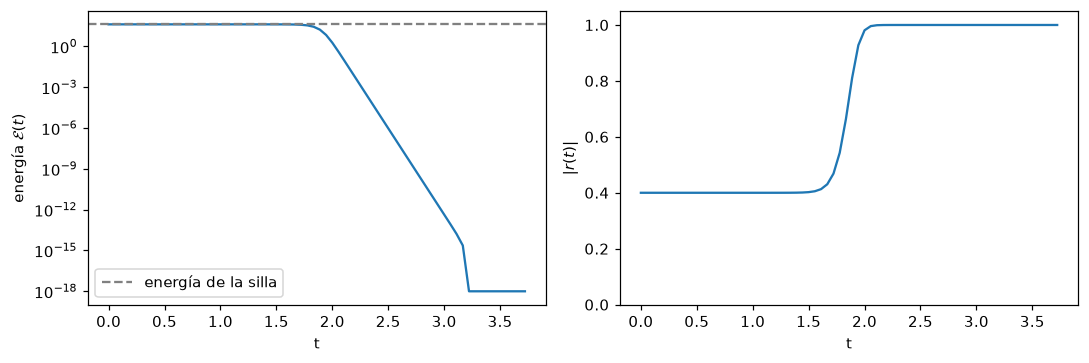

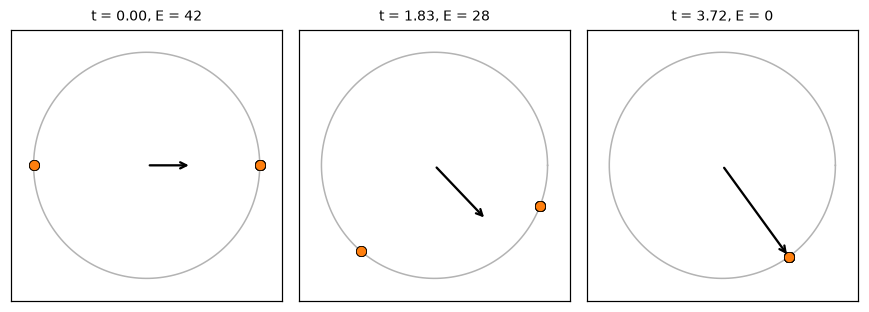

In [ ]:
m = 3
silla = np.where(np.arange(n) < m, np.pi, 0.0)

exacta = simular(silla, W)
print(f"exactamente en la silla: ‖velocidad‖ = {np.linalg.norm(velocidad(silla, W)):.1e}, pasos = {exacta['pasos']}, E final = {energia(exacta['theta'], W):.1f}  → se queda")

con_ruido = simular(silla + 1e-6 * rng.standard_normal(n), W)
print(f"silla + ruido 1e-6: pasos = {con_ruido['pasos']}, E final = {con_ruido['E'][-1]:.1e}, tipo final: {clasificar(con_ruido['theta'], W)[0]}  → escapa y sincroniza")

t = con_ruido["t"]
E = con_ruido["E"]
r = con_ruido["r"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].semilogy(t, np.maximum(E, 1e-18))
ax[0].axhline(energia(silla, W), ls="--", color="0.5", label="energía de la silla")
ax[0].set(ylabel=r"energía $\mathcal{E}(t)$", xlabel="t")
ax[0].legend()
ax[1].plot(t, np.abs(r))
ax[1].set(ylabel=r"$|r(t)|$", xlabel="t", ylim=(0, 1.05))
plt.tight_layout()
plt.show()

indices = [0, int(np.argmax(np.abs(np.diff(E)))), len(t) - 1]
fig, ax = plt.subplots(1, 3, figsize=(8, 2.8))
for eje, i in zip(ax, indices):
    dibujar_circulo(eje, con_ruido["historia"][i], f"t = {t[i]:.2f}, E = {E[i]:.2g}")
plt.tight_layout()
plt.show()

### 1.7 Conclusiones

- El simulador baja la energía en cada paso y siempre se detiene en un equilibrio.
- En $K_n$, **todas** las corridas al azar sincronizan, y el Hessiano del punto final confirma un **mínimo estricto** (el Laplaciano de $K_n$).
- Los otros puntos críticos (las configuraciones $\{\psi, \psi+\pi\}$ y las de $r=0$) existen, pero tienen autovalores negativos: son **sillas o máximos**. Arrancando exactamente ahí la bolita se queda; con el menor ruido, escapa.
- Esto es lo que significa que el paisaje de $K_n$ es **benigno**.

**Calentamiento 2** ($C_n$, $n\ge5$): el mismo pipeline (`simular` + `clasificar`) con `W` del ciclo. Ahí esperamos que una fracción de las corridas termine en un **twisted state** y que `clasificar` diga "mínimo estricto" con $\mathcal{E}>0$: un pozo trampa.

## 2. Calentamiento 2: el ciclo $C_n$

**Objetivo** (slide 26/34): repetir lo mismo en el ciclo $C_n$ con $n \ge 5$, encontrar los **twisted states estables** y verificar su estabilidad con el **espectro del Hessiano**.

Reutilizamos todo lo de la sección 1 (`velocidad`, `energia`, `hessiano`, `simular`, `clasificar`, `dibujar_circulo`); solo cambia la matriz `W`.

### 2.1 Recordatorio

- En $C_n$ cada vértice $v$ tiene dos vecinos, $v-1$ y $v+1$ (índices módulo $n$).
- **Twisted state** con $q$ vueltas: $\theta_v = \dfrac{2\pi q v}{n}$. Todas las aristas tienen la misma diferencia $d = \dfrac{2\pi q}{n}$.
- Energía: $\mathcal{E} = n\,(1-\cos d)$. Es $0$ solo si $q = 0$ (sincronizado).
- **Hessiano.** El peso de cada arista es $\cos(\theta_u-\theta_v) = \cos(\pm d) = \cos d$, igual para todas. Entonces
$$H = \cos d \cdot L_{C_n},$$
  donde $L_{C_n}$ es el Laplaciano del ciclo: $(L x)_v = 2x_v - x_{v-1} - x_{v+1}$.
- Los autovectores de $L_{C_n}$ son las ondas $x_v = e^{2\pi i k v/n}$, con autovalores $2 - 2\cos(2\pi k/n)$, $k = 0, \dots, n-1$. Por lo tanto
$$\boxed{\ \lambda_k(H) = \cos\!\Big(\frac{2\pi q}{n}\Big)\Big(2 - 2\cos\frac{2\pi k}{n}\Big)\ }$$
  - $k=0$ da el $0$ de la rotación global;
  - todos los demás tienen **el signo de $\cos d$**.
- Conclusión: el twisted state es **mínimo estricto** si $\cos d > 0 \iff |q| < n/4$, **máximo** si $|q| > n/4$, y **degenerado** si $|q| = n/4$ (como $n=4$, $q=1$).

### 2.2 Funciones nuevas

- `grafo_ciclo(n)`: matriz de adyacencia de $C_n$.
- `twisted_state(n, q)`: la configuración $\theta_v = 2\pi q v/n$.
- `winding_number(theta)`: cuántas vueltas dan las fases al recorrer el ciclo,
$$q = \frac{1}{2\pi}\sum_v \operatorname{wrap}(\theta_{v+1}-\theta_v),$$
  donde cada diferencia se lleva a $(-\pi, \pi]$. Siempre da un entero.
- `dibujar_ciclo`: como `dibujar_circulo`, pero dibujando también las aristas del ciclo (así se ve el polígono "enroscado").

In [11]:
def grafo_ciclo(n):
    """C_n: cada v conectado con v − 1 y v + 1 (módulo n)."""
    W = np.zeros((n, n))
    v = np.arange(n)
    W[v, (v + 1) % n] = 1
    W[(v + 1) % n, v] = 1
    return W


def twisted_state(n, q):
    """θ_v = 2π q v / n."""
    return 2 * np.pi * q * np.arange(n) / n


def winding_number(theta):
    """q = (1/2π) Σ_v wrap(θ_{v+1} − θ_v), recorriendo el ciclo una vez."""
    saltos = wrap(np.roll(theta, -1) - theta)
    return int(np.rint(saltos.sum() / (2 * np.pi)))


def dibujar_ciclo(ax, theta, titulo=""):
    """Como dibujar_circulo, más las aristas del ciclo v → v + 1."""
    z = np.exp(1j * np.append(theta, theta[0]))
    ax.plot(z.real, z.imag, color="tab:blue", lw=0.8, alpha=0.6, zorder=2)
    dibujar_circulo(ax, theta, titulo)

### 2.3 Chequeos de sanidad

Para $n = 9$ y $q = -4, \dots, 4$ verificamos que:

1. el twisted state es un **equilibrio** ($\|\dot\theta\| \approx 0$);
2. `winding_number` devuelve el $q$ correcto;
3. los autovalores del Hessiano coinciden con la **fórmula cerrada** de 2.1.

In [ ]:
n = 9
W = grafo_ciclo(n)
k = np.arange(n)

print(f"{'q':>3} {'‖θ̇‖':>9} {'winding':>8} {'‖autoval. − fórmula‖':>21}")
for q in range(-4, 5):
    theta = twisted_state(n, q)
    autovalores = np.linalg.eigvalsh(hessiano(theta, W))
    formula = np.sort(np.cos(2 * np.pi * q / n) * (2 - 2 * np.cos(2 * np.pi * k / n)))
    print(f"{q:>3} {np.linalg.norm(velocidad(theta, W)):>9.1e} {winding_number(theta):>8} {np.linalg.norm(autovalores - formula):>21.1e}")

  q      ‖θ̇‖  winding  ‖autoval. − fórmula‖
 -4   3.0e-15       -4               1.7e-15
 -3   3.1e-15       -3               2.4e-15
 -2   3.5e-16       -2               7.8e-16
 -1   6.3e-16       -1               2.1e-15
  0   0.0e+00        0               1.6e-15
  1   6.3e-16        1               2.1e-15
  2   3.5e-16        2               7.8e-16
  3   3.1e-15        3               2.4e-15
  4   3.0e-15        4               1.7e-15


### 2.4 Tabla de estabilidad

Para cada $n = 3, \dots, 12$ y cada $q = 0, \dots, \lfloor n/2 \rfloor$ clasificamos el twisted state con `clasificar` y lo comparamos con la predicción de 2.1 (signo de $\cos(2\pi q/n)$).

Junto a la etiqueta mostramos el **número que la decide**: $\lambda_{\min}$, el autovalor no nulo más chico del Hessiano (sacando el $0$ de la rotación global).

- $\lambda_{\min} > 0$ → todos los demás también son positivos → **mínimo estricto**.
- $\lambda_{\min} < 0$ → hay una dirección por donde bajar → **no** es mínimo.
- $\lambda_{\min} = 0$ → degenerado.

Por la fórmula de 2.1, en los mínimos ($\cos d > 0$) el más chico es el de $k = 1$:
$$\lambda_{\min} = \cos\!\Big(\frac{2\pi q}{n}\Big)\Big(2-2\cos\frac{2\pi}{n}\Big).$$

Leyenda: **mín** = mínimo estricto, **máx** = máximo, **deg** = degenerado. Un `✗` marcaría un desacuerdo con la predicción.

In [13]:
ABREVIATURA = {
    "mínimo estricto": "mín",
    "máximo estricto": "máx",
    "máximo (degenerado)": "máx",
    "silla": "silla",
    "degenerado": "deg",
}


def tipo_predicho_ciclo(n, q):
    """Tipo del twisted state q en C_n según el signo de cos(2πq/n): mín, máx o deg."""
    c = np.cos(2 * np.pi * q / n)
    if c > 1e-12:
        return "mín"
    if c < -1e-12:
        return "máx"
    return "deg"


def autovalor_no_nulo_min(autovalores):
    """Menor autovalor sacando el más cercano a 0 (la rotación global)."""
    resto = np.delete(autovalores, np.argmin(np.abs(autovalores)))
    menor = resto.min()
    return menor if abs(menor) > 1e-12 else 0.0


print("tipo y λ_min de cada twisted state\n")
encabezado = "n \\ q "
for q in range(7):
    encabezado += f"{q:>13}"
print(encabezado)

coinciden = 0
total = 0
error = 0.0
for n in range(3, 13):
    W = grafo_ciclo(n)
    fila = f"{n:>5} "
    for q in range(n // 2 + 1):
        tipo, autovalores = clasificar(twisted_state(n, q), W)
        obtenido = ABREVIATURA[tipo]
        lam = autovalor_no_nulo_min(autovalores)
        ok = obtenido == tipo_predicho_ciclo(n, q)
        coinciden += ok
        total += 1
        celda = f"{obtenido} {lam:+.3f}" + ("" if ok else " ✗")
        fila += f"{celda:>13}"
        if obtenido == "mín":
            formula = np.cos(2 * np.pi * q / n) * (2 - 2 * np.cos(2 * np.pi / n))
            error = max(error, abs(lam - formula))
    print(fila)
print(f"\ncoincide con |q| < n/4 → mín, |q| > n/4 → máx, |q| = n/4 → deg: {coinciden}/{total}")
print(f"máx |λ_min − cos(2πq/n)(2−2cos(2π/n))| en los mínimos = {error:.1e}")

tipo y λ_min de cada twisted state

n \ q             0            1            2            3            4            5            6
    3    mín +3.000   máx -1.500
    4    mín +2.000   deg +0.000   máx -4.000
    5    mín +1.382   mín +0.427   máx -2.927
    6    mín +1.000   mín +0.500   máx -2.000   máx -4.000
    7    mín +0.753   mín +0.470   máx -0.846   máx -3.425
    8    mín +0.586   mín +0.414   deg +0.000   máx -2.828   máx -4.000
    9    mín +0.468   mín +0.358   mín +0.081   máx -1.940   máx -3.645
   10    mín +0.382   mín +0.309   mín +0.118   máx -1.236   máx -3.236   máx -4.000
   11    mín +0.317   mín +0.267   mín +0.132   máx -0.558   máx -2.566   máx -3.760
   12    mín +0.268   mín +0.232   mín +0.134   deg +0.000   máx -2.000   máx -3.464   máx -4.000

coincide con |q| < n/4 → mín, |q| > n/4 → máx, |q| = n/4 → deg: 45/45
máx |λ_min − cos(2πq/n)(2−2cos(2π/n))| en los mínimos = 8.9e-16


**Cómo leer la tabla.**

- La columna $q = 0$ es el estado sincronizado: siempre mínimo.
- Para $n \le 4$ no hay **ningún** twisted state $q \neq 0$ que sea mínimo: $n=3$ da máximo y $n=4$ da degenerado (en la cuenta a tercer orden vimos que en realidad es una silla).
- A partir de $n = 5$ aparece $q = 1$ como **mínimo estricto con $\mathcal{E} > 0$**: un pozo trampa. Por eso $C_n$ con $n \ge 5$ **no sincroniza globalmente**.
- Al crecer $n$ caben más trampas: todos los $q$ con $|q| < n/4$.
- Pero los pozos son cada vez más **playos**: $\lambda_{\min}$ baja al crecer $n$ (del orden de $4\pi^2/n^2$), y para un $n$ fijo baja al acercarse $q$ al borde $n/4$ (p. ej. $n=9$, $q=2$: $\lambda_{\min} \approx 0.08$).
- Los twisted states nunca son sillas: todos los autovalores (salvo el $0$) tienen el signo de $\cos d$. Las sillas de $C_n$ son otros equilibrios, con diferencias no todas iguales.

### 2.5 Experimento A: una corrida que queda atrapada

$n = 20$, condiciones iniciales al azar, hasta encontrar una corrida que **no** sincronice (termine con $q \neq 0$). Miramos:

- la energía, que se estanca en $n(1-\cos d) > 0$ en vez de ir a $0$;
- el winding number $q(t)$ a lo largo de la corrida;
- la **fase acumulada** a lo largo del ciclo al final: si sumamos las diferencias entre vecinos, $\sum_{j<v}\operatorname{wrap}(\theta_{j+1}-\theta_j)$, un twisted state da una **escalera recta** de pendiente $2\pi q/n$;
- las partículas en el círculo con las aristas del ciclo: al final quedan equiespaciadas, dando $q$ vueltas.

pasos: 965, convergió: True
q inicial = 3,  q final = 1
E final = 0.978870   fórmula n(1−cos(2πq/n)) = 0.978870
clasificación del punto final: mínimo estricto  (autovalor positivo más chico = 0.0931)


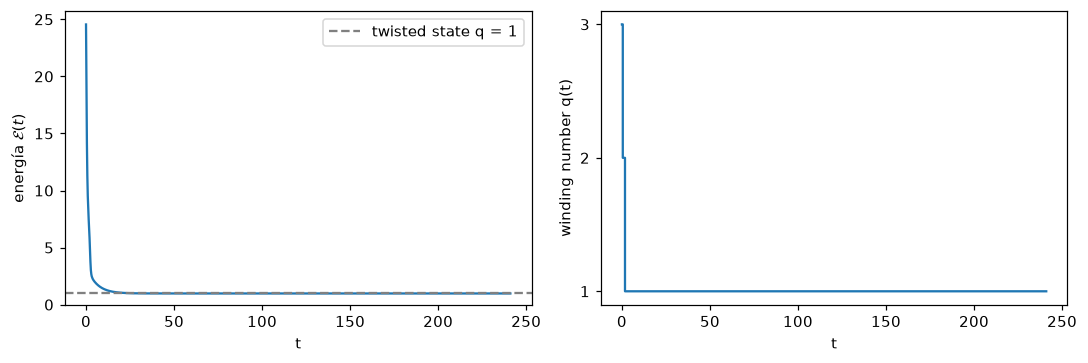

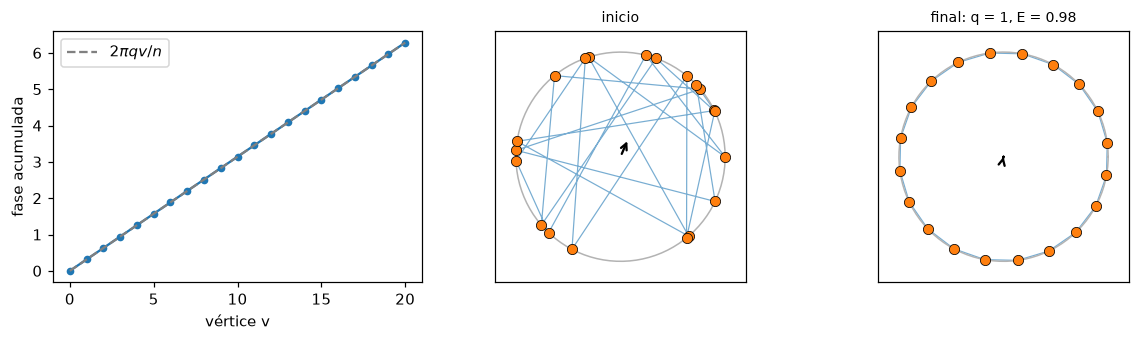

In [14]:
n = 20
W = grafo_ciclo(n)
while True:
    theta0 = rng.uniform(-np.pi, np.pi, n)
    sim = simular(theta0, W)
    q = winding_number(sim["theta"])
    if q != 0:
        break

t = sim["t"]
E = sim["E"]
E_twisted = n * (1 - np.cos(2 * np.pi * q / n))
tipo, autovalores = clasificar(sim["theta"], W)
print(f"pasos: {sim['pasos']}, convergió: {sim['convergio']}")
print(f"q inicial = {winding_number(theta0)},  q final = {q}")
print(f"E final = {E[-1]:.6f}   fórmula n(1−cos(2πq/n)) = {E_twisted:.6f}")
print(f"clasificación del punto final: {tipo}  (autovalor positivo más chico = {autovalores[1]:.4f})")

qs_tiempo = []
for theta_t in sim["historia"]:
    qs_tiempo.append(winding_number(theta_t))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(t, E)
ax[0].axhline(E_twisted, ls="--", color="0.5", label=f"twisted state q = {q}")
ax[0].set(ylabel=r"energía $\mathcal{E}(t)$", xlabel="t", ylim=(0, None))
ax[0].legend()
ax[1].step(t, qs_tiempo, where="post")
ax[1].set(ylabel="winding number q(t)", xlabel="t")
ax[1].yaxis.get_major_locator().set_params(integer=True)
plt.tight_layout()
plt.show()

theta_final = sim["theta"]
saltos = wrap(np.roll(theta_final, -1) - theta_final)
fase_acumulada = np.concatenate([[0], np.cumsum(saltos)])
vertices = np.arange(n + 1)
fig = plt.figure(figsize=(11, 3.2))
ax0 = fig.add_subplot(1, 3, 1)
ax0.plot(vertices, fase_acumulada, "o-", ms=4)
ax0.plot(vertices, 2 * np.pi * q * vertices / n, ls="--", color="0.5", label=r"$2\pi q v/n$")
ax0.set(xlabel="vértice v", ylabel="fase acumulada")
ax0.legend()
dibujar_ciclo(fig.add_subplot(1, 3, 2), theta0, "inicio")
dibujar_ciclo(fig.add_subplot(1, 3, 3), theta_final, f"final: q = {q}, E = {E[-1]:.2f}")
plt.tight_layout()
plt.show()

### 2.6 Experimento B: ¿qué fracción sincroniza?

Para cada $n \in \{5, 8, 10, 15, 20, 30, 40\}$ largamos 200 condiciones iniciales al azar y registramos el $q$ final. Para cada corrida chequeamos además que el final sea un **mínimo estricto**, con $|q| < n/4$ y energía $n(1-\cos(2\pi q/n))$.

También contamos cuántas veces el $q$ final coincide con el $q$ de la condición inicial: ¿la trampa en la que se cae queda decidida desde el arranque, o el flujo cambia el winding en el camino?

In [ ]:
ns = [5, 8, 10, 15, 20, 30, 40]
corridas = 200
q_final = {}

print(f"{'n':>4} {'sincronizan':>12} {'mín. estricto':>14} {'|q|<n/4':>9} {'E = fórmula':>12} {'q fin = q ini':>14}")
for n in ns:
    W = grafo_ciclo(n)
    qs = []
    estrictos = 0
    adentro = 0
    energia_ok = 0
    iguales = 0
    for _ in range(corridas):
        theta0 = rng.uniform(-np.pi, np.pi, n)
        sim = simular(theta0, W, tol=1e-8, guardar=False)
        q = winding_number(sim["theta"])
        qs.append(q)
        estrictos += clasificar(sim["theta"], W)[0] == "mínimo estricto"
        adentro += abs(q) < n / 4
        energia_ok += abs(energia(sim["theta"], W) - n * (1 - np.cos(2 * np.pi * q / n))) < 1e-6
        iguales += q == winding_number(theta0)
    q_final[n] = np.array(qs)
    sincronizan = np.mean(q_final[n] == 0)
    print(f"{n:>4} {sincronizan:>11.0%} {estrictos:>9}/{corridas} {adentro:>5}/{corridas} {energia_ok:>8}/{corridas} {iguales:>10}/{corridas}")

   n  sincronizan  mín. estricto   |q|<n/4  E = fórmula  q fin = q ini
   5         93%       200/200   200/200      200/200        127/200


   8         76%       200/200   200/200      200/200        114/200


  10         68%       200/200   200/200      200/200        116/200


  15         55%       200/200   200/200      200/200         84/200


  20         46%       200/200   200/200      200/200         81/200


  30         38%       200/200   200/200      200/200         66/200


  40         34%       200/200   200/200      200/200         56/200


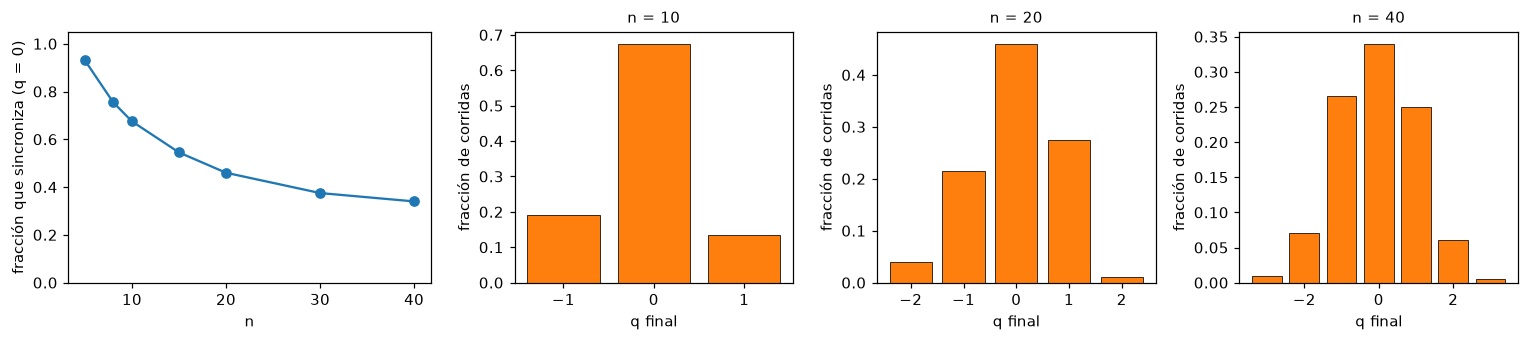

In [16]:
fraccion_sincronizada = []
for n in ns:
    fraccion_sincronizada.append(np.mean(q_final[n] == 0))

fig, ax = plt.subplots(1, 4, figsize=(14, 3.2), gridspec_kw={"width_ratios": [1.3, 1, 1, 1]})
ax[0].plot(ns, fraccion_sincronizada, "o-")
ax[0].set(xlabel="n", ylabel="fracción que sincroniza (q = 0)", ylim=(0, 1.05))
for eje, n in zip(ax[1:], [10, 20, 40]):
    valores, cuentas = np.unique(q_final[n], return_counts=True)
    eje.bar(valores, cuentas / corridas, color="tab:orange", edgecolor="k", lw=0.5)
    eje.set(xlabel="q final", ylabel="fracción de corridas")
    eje.set_title(f"n = {n}", fontsize=10)
    eje.xaxis.get_major_locator().set_params(integer=True)
plt.tight_layout()
plt.show()

### 2.7 Experimento C: escapar de un twisted state inestable

$n = 8$, $q = 3$: la diferencia entre vecinos es $d = 135° > 90°$, así que el twisted state es un **máximo**. Arrancamos ahí con un ruido de $10^{-6}$.

El winding number solo puede cambiar **de a saltos enteros**, cuando alguna arista pasa por diferencia $\pi$. Las líneas punteadas marcan la energía de cada twisted state $n(1-\cos(2\pi q/n))$.

Ojo: $q(t)$ es un número **topológico**, no dice si estamos sincronizados. Durante la caída se puede pasar por $q = 0$ con la energía todavía alta y seguir de largo.

tipo del twisted state q = 3: máximo estricto
q final = -1, E final = 2.3431, tipo final: mínimo estricto


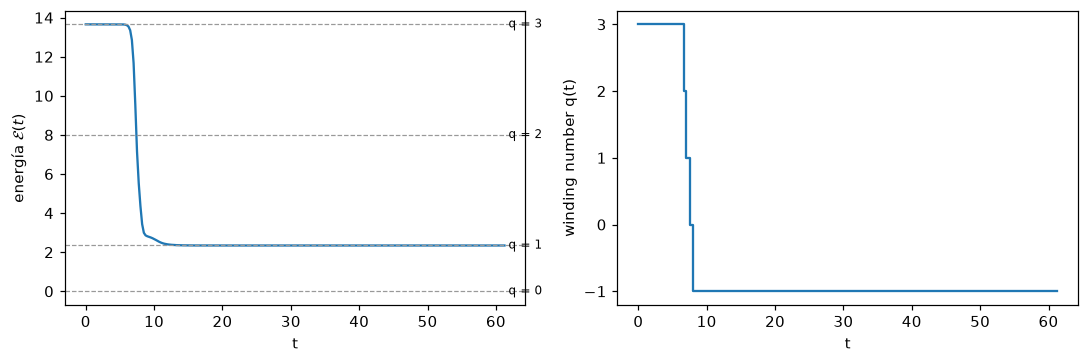

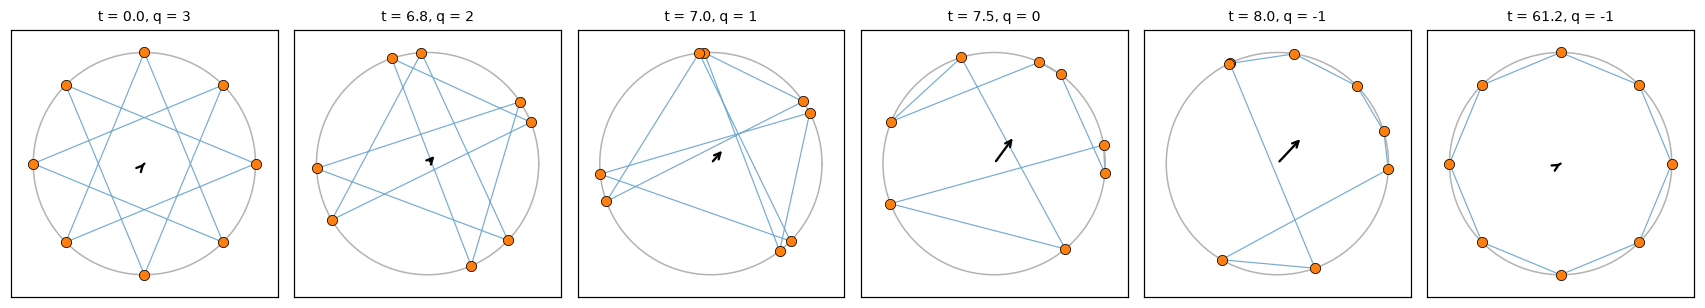

In [17]:
n = 8
q0 = 3
W = grafo_ciclo(n)
inicio = twisted_state(n, q0)
print("tipo del twisted state q = 3:", clasificar(inicio, W)[0])

sim = simular(inicio + 1e-6 * rng.standard_normal(n), W)
t = sim["t"]
E = sim["E"]
qs_tiempo = []
for theta_t in sim["historia"]:
    qs_tiempo.append(winding_number(theta_t))
print(f"q final = {qs_tiempo[-1]}, E final = {E[-1]:.4f}, tipo final: {clasificar(sim['theta'], W)[0]}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(t, E)
for q in range(0, 4):
    E_q = n * (1 - np.cos(2 * np.pi * q / n))
    ax[0].axhline(E_q, ls="--", color="0.6", lw=0.8)
    ax[0].text(t[-1], E_q, f" q = {q}", va="center", fontsize=8)
ax[0].set(ylabel=r"energía $\mathcal{E}(t)$", xlabel="t")
ax[1].step(t, qs_tiempo, where="post")
ax[1].set(ylabel="winding number q(t)", xlabel="t")
ax[1].yaxis.get_major_locator().set_params(integer=True)
plt.tight_layout()
plt.show()

# fotos al inicio, en cada salto de q y al final
indices = [0]
for i in range(1, len(qs_tiempo)):
    if qs_tiempo[i] != qs_tiempo[i - 1]:
        indices.append(i)
indices.append(len(t) - 1)
fig, ax = plt.subplots(1, len(indices), figsize=(2.6 * len(indices), 2.8))
for eje, i in zip(np.atleast_1d(ax), indices):
    dibujar_ciclo(eje, sim["historia"][i], f"t = {t[i]:.1f}, q = {qs_tiempo[i]}")
plt.tight_layout()
plt.show()

### 2.8 Conclusiones

- Los twisted states de $C_n$ son equilibrios, y su Hessiano es exactamente $\cos(2\pi q/n)\,L_{C_n}$: el chequeo numérico coincide con la fórmula cerrada.
- Son **mínimos estrictos** si $|q| < n/4$, máximos si $|q| > n/4$ y degenerados en el borde. Para $n \ge 5$ el de $q = 1$ es un pozo trampa con $\mathcal{E} > 0$: **$C_n$ no sincroniza globalmente**.
- En las simulaciones, todas las corridas terminan en un mínimo estricto: o el sincronizado, o un twisted state con $|q| < n/4$, con exactamente la energía que predice la fórmula. La fracción que sincroniza **baja** al crecer $n$ (de ~90 % en $n=5$ a ~1/3 en $n=40$), porque caben más trampas y sus cuencas ocupan más lugar.
- El $q$ final coincide con el de la condición inicial solo en una parte de las corridas: un inicio al azar tiene muchas aristas con diferencias cerca de $\pi$, y al principio del flujo el winding cambia. La trampa no queda decidida en el arranque.
- Partiendo de un twisted state inestable, el winding cambia de a saltos de $\pm1$ (alguna arista pasa por $\pi$) hasta caer en una trampa estable o en la sincronización. Puede cruzar $q = 0$ sin detenerse.

**Calentamiento 3** ($C_{n,k}$: $k$ vecinos de cada lado, grado $2k$): los twisted states siguen siendo equilibrios, pero ahora un vértice tiene vecinos a distancia $d, 2d, \dots, kd$. ¿Hasta qué $k$ hay alguno estable? Ahí empieza la pregunta de cuánta conectividad puede tener un grafo y todavía esconder una trampa.

## 3. Calentamiento 3: el grafo circulante $C_{n,k}$

**Objetivo** (slide 26/34): construir $C_{n,k}$ ($k$ vecinos de cada lado, grado $2k$), verificar que los twisted states siguen siendo equilibrios y responder: **¿hasta qué $k$ hay alguno estable?**

Este es el primer calentamiento que toca el problema de verdad. $C_{n,k}$ tiene conectividad
$$\mu = \frac{\deg}{n-1} = \frac{2k}{n-1},$$
así que si encontramos un twisted state estable (una trampa) en $C_{n,k}$, ese grafo **no sincroniza** con conectividad $2k/(n-1)$, y eso da una **cota inferior** para $\mu_c$.

### 3.1 Recordatorio

- En $C_{n,k}$ cada vértice $v$ está conectado con $v\pm1, v\pm2, \dots, v\pm k$ (módulo $n$), con $k \le (n-1)/2$.
  - $k = 1$ es el ciclo $C_n$;
  - $2k = n-1$ es el completo $K_n$.
- **Twisted state** $\theta_v = 2\pi q v/n$, con $d = 2\pi q/n$. Un vecino a distancia $j$ tiene diferencia $\pm jd$.
- **Es equilibrio para todo $k$:** los dos vecinos a distancia $j$ tiran con $\sin(jd)$ y $\sin(-jd)$, que se cancelan.
- **Energía:** $\mathcal{E} = n\sum_{j=1}^{k}\bigl(1-\cos(jd)\bigr)$.
- **Hessiano:** sigue siendo un Laplaciano con pesos, ahora con peso $\cos(jd)$ en las aristas de distancia $j$. Es **circulante** (igual visto desde cada vértice), así que sus autovectores siguen siendo las ondas $e^{2\pi i m v/n}$, con autovalores
$$\boxed{\ \lambda_m = \sum_{j=1}^{k} \cos(jd)\,\Big(2 - 2\cos\frac{2\pi j m}{n}\Big)\ }, \qquad m = 0, \dots, n-1.$$
  Con $k=1$ es la fórmula de 2.1.
- **La novedad:** en $C_n$ todos los pesos eran $\cos d$, con un único signo. Ahora las aristas largas pueden tener $jd > 90°$ y **peso negativo**. Al mezclarse signos:
  - la estabilidad ya no es simplemente $|q| < n/4$;
  - aparecen twisted states que son **sillas**;
  - y sumar vecinos lejanos termina **desestabilizando** las trampas.

### 3.2 Funciones nuevas

- `grafo_circulante(n, k)`: matriz de adyacencia de $C_{n,k}$.
- `autovalores_twisted(n, k, q)`: los autovalores del Hessiano en el twisted state, con la fórmula cerrada de 3.1 (sin armar la matriz, así que es rápido para $n$ grande).

Reutilizamos `twisted_state`, `winding_number`, `clasificar`, `ABREVIATURA` y `autovalor_no_nulo_min` de la sección 2.

In [18]:
def grafo_circulante(n, k):
    """C_{n,k}: cada v conectado con v ± 1, …, v ± k (módulo n)."""
    W = np.zeros((n, n))
    v = np.arange(n)
    for j in range(1, k + 1):
        W[v, (v + j) % n] = 1
        W[(v + j) % n, v] = 1
    return W


def autovalores_twisted(n, k, q):
    """Fórmula cerrada en C_{n,k}: λ_m = Σ_j cos(j d)(2 − 2 cos(2π j m / n)), d = 2πq/n, m = 0..n−1."""
    d = 2 * np.pi * q / n
    m = np.arange(n)[:, None]
    j = np.arange(1, k + 1)[None, :]
    terminos = np.cos(j * d) * (2 - 2 * np.cos(2 * np.pi * j * m / n))
    return terminos.sum(axis=1)

### 3.3 Chequeos de sanidad

1. $C_{n,1}$ es el ciclo y $C_{n,(n-1)/2}$ es el completo.
2. Para $n = 15$, varios $k$ y $q$: el twisted state es **equilibrio**, su energía es $n\sum_j(1-\cos jd)$ y el espectro del Hessiano coincide con la **fórmula cerrada**.

In [ ]:
print("C_{n,1} == C_n:", np.array_equal(grafo_circulante(9, 1), grafo_ciclo(9)))
print("C_{n,(n−1)/2} == K_n:", np.array_equal(grafo_circulante(9, 4), grafo_completo(9)))

n = 15
print(f"\n{'k':>2} {'q':>2} {'‖θ̇‖':>9} {'|E − fórmula|':>14} {'‖autoval. − fórmula‖':>21}")
for k in [2, 4, 7]:
    W = grafo_circulante(n, k)
    for q in [1, 2, 5]:
        theta = twisted_state(n, q)
        d = 2 * np.pi * q / n
        suma = 0.0
        for j in range(1, k + 1):
            suma += 1 - np.cos(j * d)
        E_formula = n * suma
        autovalores = np.linalg.eigvalsh(hessiano(theta, W))
        error_autovalores = np.linalg.norm(autovalores - np.sort(autovalores_twisted(n, k, q)))
        print(f"{k:>2} {q:>2} {np.linalg.norm(velocidad(theta, W)):>9.1e} {abs(energia(theta, W) - E_formula):>14.1e} {error_autovalores:>21.1e}")

C_{n,1} == C_n: True
C_{n,(n−1)/2} == K_n: True

 k  q      ‖θ̇‖  |E − fórmula|  ‖autoval. − fórmula‖
 2  1   3.0e-15        8.9e-16               5.2e-15
 2  2   1.7e-15        3.6e-15               3.1e-15
 2  5   1.3e-14        0.0e+00               8.4e-15
 4  1   3.8e-15        7.1e-15               6.6e-15
 4  2   8.3e-15        1.4e-14               5.6e-15
 4  5   9.5e-15        1.4e-14               1.3e-14
 7  1   4.1e-15        0.0e+00               1.1e-14
 7  2   8.0e-15        1.4e-14               7.8e-15
 7  5   1.5e-14        1.4e-14               1.2e-14


### 3.4 Tabla de estabilidad

Para $n = 20$, cada $k = 1, \dots, 9$ y cada $q = 0, \dots, 5$: tipo según `clasificar` y $\lambda_{\min}$ (el autovalor no nulo más chico), con el mismo formato que en 2.4. La última columna es la conectividad $\mu = 2k/(n-1)$.

In [20]:
n = 20
print("n = 20: tipo y λ_min de cada twisted state\n")
encabezado = f"{'k':>2} {'μ':>5} "
for q in range(6):
    encabezado += f"{f'q = {q}':>15}"
print(encabezado)
for k in range(1, (n - 1) // 2 + 1):
    W = grafo_circulante(n, k)
    fila = f"{k:>2} {2 * k / (n - 1):>5.2f} "
    for q in range(6):
        tipo, autovalores = clasificar(twisted_state(n, q), W)
        celda = f"{ABREVIATURA[tipo]} {autovalor_no_nulo_min(autovalores):+.3f}"
        fila += f"{celda:>15}"
    print(fila)

n = 20: tipo y λ_min de cada twisted state

 k     μ           q = 0          q = 1          q = 2          q = 3          q = 4          q = 5
 1  0.11      mín +0.098     mín +0.093     mín +0.079     mín +0.058     mín +0.030     deg +0.000
 2  0.21      mín +0.480     mín +0.402     mín +0.197   silla -0.324   silla -2.618     máx -4.000
 3  0.32      mín +1.304     mín +0.887   silla -0.073   silla -4.036     máx -5.427     máx -4.000
 4  0.42      mín +2.686     mín +1.314   silla -3.000     máx -6.963     máx -5.000   silla -4.000
 5  0.53      mín +4.686     mín +1.314   silla -7.000     máx -6.963   silla -5.000   silla -4.000
 6  0.63      mín +7.304     mín +0.505     máx -9.927   silla -6.654   silla -4.573   silla -8.000
 7  0.74     mín +10.480   silla -1.362    máx -10.736   silla -6.560   silla -7.500   silla -8.000
 8  0.84     mín +14.098   silla -4.289    máx -10.309   silla -6.133    máx -10.427   silla -8.000
 9  0.95     mín +18.000   silla -8.000    máx -10.000  

**Cómo leer la tabla.**

- La fila $k = 1$ es el ciclo $C_{20}$ de la sección 2: mínimos para $q < 5$.
- Al agregar vecinos, los $q$ grandes son los primeros en dejar de ser mínimos: con más vueltas, $d$ es más grande y aparecen antes aristas con $jd > 90°$.
- Aparecen **sillas** (algunos autovalores positivos y otros negativos), algo que en $C_n$ no pasaba.
- El que más aguanta es **$q = 1$**: es mínimo estricto hasta $k = 6$ ($\mu \approx 0.63$) y deja de serlo en $k = 7$. Para $k \ge 7$ ningún twisted state es trampa.
- En la columna $q = 1$, $\lambda_{\min}$ primero crece (más aristas que "sostienen") y después cae (las aristas largas, con $\cos(jd) < 0$, empujan hacia afuera) hasta cruzar el $0$.

### 3.5 ¿Hasta qué $k$?

Para cada $n$ definimos $k_{\max}(n)$ como el **mayor $k$ con algún twisted state $q \neq 0$ que sea mínimo estricto**. Con la fórmula cerrada de 3.1 lo calculamos para $n = 5, \dots, 200$, mirando todos los $q$. Además chequeamos tres cosas:

- que el conjunto de $k$ estables sea un **intervalo** $1, \dots, k_{\max}$ (no hay "huecos");
- **qué $q$** es el último en sobrevivir;
- que para $n \le 30$ la fórmula dé lo mismo que `clasificar` sobre el Hessiano numérico.

In [21]:
def es_trampa(n, k, q):
    """¿El twisted state q es mínimo estricto en C_{n,k}? (todos los λ_m con m ≠ 0 positivos)."""
    return autovalores_twisted(n, k, q)[1:].min() > 1e-12


def k_max(n):
    """Mayor k con algún twisted state q ≠ 0 estable en C_{n,k}.

    Devuelve (k_max, lista de k estables, q estables en k_max).
    """
    qs = range(1, n // 2 + 1)
    ks_estables = []
    for k in range(1, (n - 1) // 2 + 1):
        if any(es_trampa(n, k, q) for q in qs):
            ks_estables.append(k)
    if not ks_estables:
        return 0, [], []
    ultimo = ks_estables[-1]
    qs_ultimo = []
    for q in qs:
        if es_trampa(n, ultimo, q):
            qs_ultimo.append(q)
    return ultimo, ks_estables, qs_ultimo


def k_max_clasificando(n):
    """Igual que k_max pero clasificando con el Hessiano numérico (sin fórmula cerrada)."""
    mejor = 0
    for k in range(1, (n - 1) // 2 + 1):
        W = grafo_circulante(n, k)
        for q in range(1, n // 2 + 1):
            if clasificar(twisted_state(n, q), W)[0] == "mínimo estricto":
                mejor = k
                break
    return mejor


ns = np.arange(5, 201)
resultados = {}
for n in ns:
    resultados[n] = k_max(n)
kmax = np.array([resultados[n][0] for n in ns])

forman_intervalo = True
qs_sobrevivientes = set()
for n in ns:
    ultimo, ks_estables, qs_ultimo = resultados[n]
    forman_intervalo = forman_intervalo and ks_estables == list(range(1, ultimo + 1))
    qs_sobrevivientes.add(tuple(qs_ultimo))
print("¿los k estables forman un intervalo 1..k_max?", forman_intervalo)
print("q que sobreviven en k_max:", sorted(qs_sobrevivientes))

coincide = True
for n in range(5, 31):
    coincide = coincide and resultados[n][0] == k_max_clasificando(n)
print("fórmula == clasificar para n = 5..30:", coincide)

print(f"\n{'n':>5} {'k_max':>6} {'k_max/n':>8} {'μ = 2k_max/(n−1)':>17}")
for n in [5, 8, 10, 20, 30, 50, 100, 200]:
    k = kmax[n - 5]
    print(f"{n:>5} {k:>6} {k / n:>8.3f} {2 * k / (n - 1):>17.3f}")

¿los k estables forman un intervalo 1..k_max? True
q que sobreviven en k_max: [(1,)]
fórmula == clasificar para n = 5..30: True

    n  k_max  k_max/n  μ = 2k_max/(n−1)
    5      1    0.200             0.500
    8      2    0.250             0.571
   10      2    0.200             0.444
   20      6    0.300             0.632
   30      9    0.300             0.621
   50     16    0.320             0.653
  100     33    0.330             0.667
  200     67    0.335             0.673


Como el último en sobrevivir es siempre $q = 1$, para $n$ grande alcanza con mirar solo ese: lo hacemos para $n$ hasta $5000$, sumando los términos de la fórmula de a uno (al pasar de $k-1$ a $k$ solo se agrega el término $j = k$) y cortando en el primer $k$ que no es estable.

n =   250   k_max =    84   k_max/n = 0.3360   μ = 0.6747
n =   300   k_max =   101   k_max/n = 0.3367   μ = 0.6756
n =   400   k_max =   135   k_max/n = 0.3375   μ = 0.6767
n =   500   k_max =   169   k_max/n = 0.3380   μ = 0.6774
n =   700   k_max =   237   k_max/n = 0.3386   μ = 0.6781
n =  1000   k_max =   339   k_max/n = 0.3390   μ = 0.6787
n =  1500   k_max =   510   k_max/n = 0.3400   μ = 0.6805
n =  2000   k_max =   680   k_max/n = 0.3400   μ = 0.6803
n =  3000   k_max =  1020   k_max/n = 0.3400   μ = 0.6802
n =  5000   k_max =  1701   k_max/n = 0.3402   μ = 0.6805


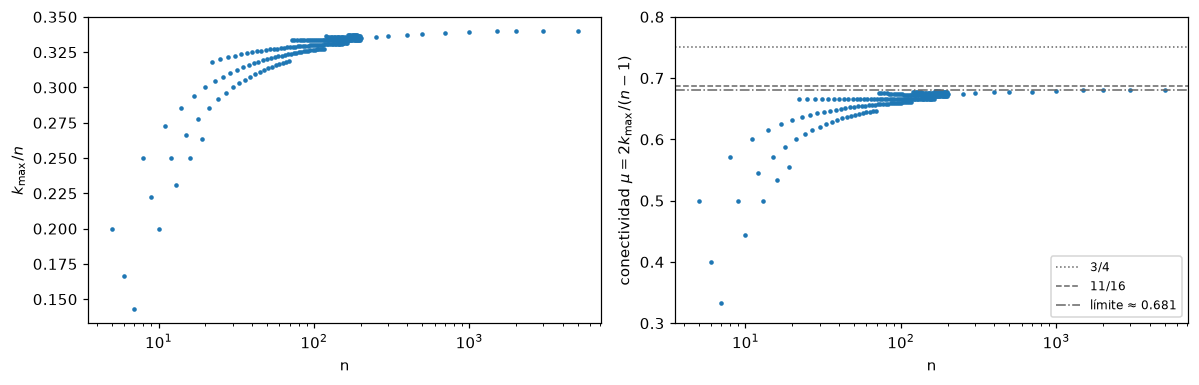

In [22]:
def k_max_q1(n):
    """k_max solo para q = 1, acumulando la suma de λ_m al crecer k (sirve para n grande)."""
    m = np.arange(n)
    d = 2 * np.pi / n
    autovalores = np.zeros(n)
    mejor = 0
    for k in range(1, (n - 1) // 2 + 1):
        autovalores += np.cos(k * d) * (2 - 2 * np.cos(2 * np.pi * k * m / n))
        if autovalores[1:].min() <= 1e-12:
            break
        mejor = k
    return mejor


ns_grandes = np.array([250, 300, 400, 500, 700, 1000, 1500, 2000, 3000, 5000])
kmax_grandes = np.array([k_max_q1(n) for n in ns_grandes])
for n, k in zip(ns_grandes, kmax_grandes):
    print(f"n = {n:>5}   k_max = {k:>5}   k_max/n = {k / n:.4f}   μ = {2 * k / (n - 1):.4f}")

todos_n = np.concatenate([ns, ns_grandes])
todos_k = np.concatenate([kmax, kmax_grandes])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].semilogx(todos_n, todos_k / todos_n, ".", ms=4)
ax[0].set(xlabel="n", ylabel=r"$k_{\max}/n$")
ax[1].semilogx(todos_n, 2 * todos_k / (todos_n - 1), ".", ms=4)
referencias = [(3 / 4, "3/4", ":"), (11 / 16, "11/16", "--"), (2 * 0.3405, "límite ≈ 0.681", "-.")]
for y, nombre, estilo in referencias:
    ax[1].axhline(y, ls=estilo, color="0.4", lw=1, label=nombre)
ax[1].set(xlabel="n", ylabel=r"conectividad $\mu = 2k_{\max}/(n-1)$", ylim=(0.3, 0.8))
ax[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

**Qué muestra.**

- El conjunto de $k$ con trampa es siempre un intervalo $1, \dots, k_{\max}$, y el último twisted state en sobrevivir es siempre el de **$q = 1$** (una sola vuelta, la diferencia más chica entre vecinos).
- $k_{\max}/n$ sube despacio hacia $\approx 0.34$, así que la conectividad máxima con trampa tiende a $\mu \approx 0.68$.
- Este es el resultado de **Wiley–Strogatz–Girvan** (2006): el twisted state $q=1$ de $C_{n,k}$ es estable mientras $k/n \lesssim 0.34$. Es la primera evidencia de que $\mu_c \ge 0.68$, y de ahí arrancan las cotas inferiores de la slide: $0.6828$ (que usa otros grafos circulantes, con vecinos que no son contiguos), luego $0.6838$ y $11/16 = 0.6875$.
- Para llegar más arriba hace falta **salir de $C_{n,k}$**: el límite $0.68$ está por debajo de $11/16$, que es justamente lo que pide la dirección A.

### 3.6 Simulaciones: ¿qué fracción sincroniza?

$n = 30$, de modo que $k_{\max} = 9$ ($\mu \approx 0.62$). Para $k = 1, \dots, 11$ largamos 200 condiciones iniciales al azar y miramos:

- la fracción que sincroniza ($q = 0$);
- si todos los finales son **mínimos estrictos**;
- si los que **no** sincronizan terminan en un twisted state, chequeando que su energía sea $n\sum_j(1-\cos(2\pi jq/n))$. Si alguno no cumpliera esto, habría trampas que no son twisted states.

Esperamos que la fracción suba con $k$ y llegue a $100\,\%$ a partir de $k = 10$.

  k     μ  sincronizan  mín. estricto  twisted (E = fórmula)  q finales


  1  0.07       75/200       200/200               200/200  -3: 1, -2: 18, -1: 47, 0: 75, 1: 53, 2: 6


  2  0.14      108/200       200/200               200/200  -2: 3, -1: 39, 0: 108, 1: 48, 2: 2


  3  0.21      137/200       200/200               200/200  -1: 31, 0: 137, 1: 32


  4  0.28      165/200       200/200               200/200  -1: 18, 0: 165, 1: 17


...

  7  0.48      197/200       200/200               200/200  -1: 1, 0: 197, 1: 2


  8  0.55      199/200       200/200               200/200  0: 199, 1: 1


  9  0.62      199/200       200/200               200/200  -1: 1, 0: 199


 10  0.69      200/200       200/200               200/200  0: 200


 11  0.76      200/200       200/200               200/200  0: 200


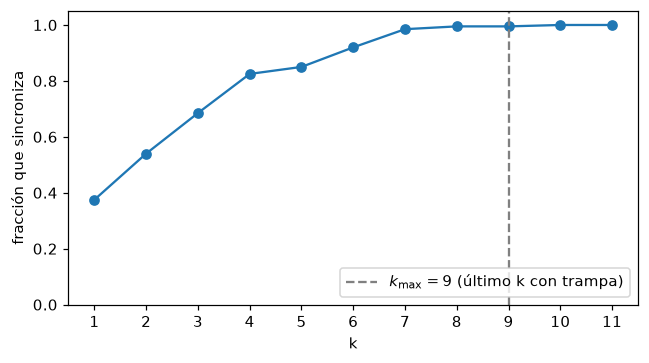

In [23]:
n = 30
ks = range(1, 12)
corridas = 200
fracciones = []

print(f"{'k':>3} {'μ':>5} {'sincronizan':>12} {'mín. estricto':>14} {'twisted (E = fórmula)':>22}  q finales")
for k in ks:
    W = grafo_circulante(n, k)
    qs = []
    estrictos = 0
    twisted = 0
    for _ in range(corridas):
        sim = simular(rng.uniform(-np.pi, np.pi, n), W, tol=1e-8, guardar=False)
        q = winding_number(sim["theta"])
        qs.append(q)
        estrictos += clasificar(sim["theta"], W)[0] == "mínimo estricto"
        suma = 0.0
        for j in range(1, k + 1):
            suma += 1 - np.cos(2 * np.pi * j * q / n)
        E_formula = n * suma
        twisted += abs(energia(sim["theta"], W) - E_formula) < 1e-6
    qs = np.array(qs)
    fracciones.append(np.mean(qs == 0))
    valores, cuentas = np.unique(qs, return_counts=True)
    detalle = ", ".join(f"{v}: {c}" for v, c in zip(valores, cuentas))
    print(f"{k:>3} {2 * k / (n - 1):>5.2f} {np.sum(qs == 0):>8}/{corridas} {estrictos:>9}/{corridas} "
          f"{twisted:>17}/{corridas}  {detalle}")

ultimo_k = k_max(n)[0]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(list(ks), fracciones, "o-")
ax.axvline(ultimo_k, ls="--", color="0.5", label=rf"$k_{{\max}} = {ultimo_k}$ (último k con trampa)")
ax.set(xlabel="k", ylabel="fracción que sincroniza", ylim=(0, 1.05), xticks=list(ks))
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Qué muestra.**

- Al crecer $k$ la fracción que sincroniza sube, y desde $k = k_{\max} + 1 = 10$ es $100\,\%$, como predice el Hessiano.
- Todos los finales son mínimos estrictos, y los que no sincronizan son twisted states. En estas corridas no aparecieron trampas de otra forma.
- Cerca de $k_{\max}$ la trampa $q = \pm1$ todavía existe, pero su cuenca es **chiquita**: pocas corridas caen ahí. Una simulación al azar casi no ve una trampa que está a punto de desaparecer. Por eso para buscar trampas con $\mu$ alto conviene analizar el Hessiano antes que tirar inicios al azar.

### 3.7 Conclusiones

- En $C_{n,k}$ los twisted states son equilibrios para todo $k$, y el espectro del Hessiano tiene fórmula cerrada: $\lambda_m = \sum_j \cos(jd)(2-2\cos(2\pi jm/n))$.
- Al agregar vecinos, las aristas largas con $jd > 90°$ tienen peso negativo y van desestabilizando las trampas. Aparecen sillas y los $q$ grandes caen primero.
- **¿Hasta qué $k$?** El último en sobrevivir es $q = 1$, estable mientras $k \le k_{\max}(n)$, con $k_{\max}/n \to 0.34$. En términos de conectividad: **$C_{n,k}$ tiene trampas hasta $\mu \approx 0.68$** (Wiley–Strogatz–Girvan). Es una cota inferior $\mu_c \gtrsim 0.68$.
- Las simulaciones coinciden: pasado $k_{\max}$ todas sincronizan, y cerca de $k_{\max}$ la trampa existe pero casi nadie cae en ella.
- **Pipeline completo:** simulador + test de estabilidad por el Hessiano + fórmula cerrada para familias circulantes. Para superar $11/16$ hay que buscar grafos **fuera de $C_{n,k}$** (dirección A).